# Hidden unfairness in clinical risk models

This notebook walks through the replication of Kearns, Neel, Roth & Wu (2018) using the `subgroup_audit` package in `src/`. The heavy lifting (training ~40 models per dataset) is done by `scripts/run_experiments.py`; here we load its saved results and re-run the parts that are quick.

In [1]:
import sys, json
sys.path.insert(0, '../src')
import numpy as np, pandas as pd
from IPython.display import Image, display
from subgroup_audit import audit as A
R = {n: json.load(open(f'../results/{n}.json')) for n in ['meps', 'diabetes', 'communities', 'adult']}

## 1. The idea in one toy example

Four cells of 400 true negatives each. Single attributes look perfectly fair; every intersection is off by 15 points.

In [2]:
rows = []
for sex in ['Male', 'Female']:
    for race in ['White', 'Black']:
        fpr = 0.4 if (sex == 'Male') == (race == 'Black') else 0.1
        rows += [{'sex': sex, 'race': race, 'y': 0, 'p': int(i < fpr * 400)} for i in range(400)]
toy = pd.DataFrame(rows)
res = A.audit(toy.y, toy.p, toy[['sex', 'race']], 'fpr', max_order=2)
pd.DataFrame(res['single_attribute'] + res['top_raw_gap'][:4])[['subgroup', 'rate', 'gap', 'weighted_gap']]

,subgroup,rate,gap,weighted_gap
0,race=Black,0.25,0.00,0.0000
1,race=White,0.25,0.00,0.0000
2,sex=Female,0.25,0.00,0.0000
3,sex=Male,0.25,0.00,0.0000
4,sex=Male & race=Black,0.40,0.15,0.0375
5,sex=Female & race=White,0.40,0.15,0.0375
6,sex=Male & race=White,0.10,-0.15,0.0375
7,sex=Female & race=Black,0.10,-0.15,0.0375


## 2. Baseline models: single attributes vs. intersections (test set)

In [3]:
def headline(name):
    out = []
    for k, m in R[name]['models'].items():
        out.append({'model': k, 'accuracy': m['overall']['accuracy'],
                    'worst single': f"{m['worst_single']['subgroup']} ({100*m['worst_single']['gap']:+.1f} pp)",
                    'worst intersection': f"{m['worst_intersection']['subgroup']} ({100*m['worst_intersection']['gap']:+.1f} pp, n={m['worst_intersection']['base_size']})",
                    'max weighted gap': m['max_weighted_gap'], 'train max weighted gap': m['train_max_weighted_gap']})
    return pd.DataFrame(out).round(4)
for n in R:
    print(n, R[n]['metric'].upper()); display(headline(n))

meps FNR


,model,accuracy,worst single,worst intersection,max weighted gap,train max weighted gap
0,logistic,0.7704,age_band=18-29 (+46.7 pp),sex=Female & race=Hispanic & age_band=18-29 (+...,0.0158,0.0150
1,boosting,0.7645,age_band=18-29 (+43.9 pp),sex=Male & race=White & age_band=30-44 (+54.3 ...,0.0163,0.0150
2,marginal_fair,0.7433,age_band=18-29 (+20.3 pp),sex=Female & race=Hispanic & age_band=18-29 (+...,0.0051,0.0039
3,subgroup_fair,0.7433,age_band=18-29 (+20.4 pp),sex=Female & race=Hispanic & age_band=18-29 (+...,0.0052,0.0038
4,subgroup_fair_boosting,0.7374,age_band=18-29 (+19.0 pp),sex=Male & race=White & age_band=30-44 (+36.2 ...,0.0044,0.0026


diabetes FNR


,model,accuracy,worst single,worst intersection,max weighted gap,train max weighted gap
0,logistic,0.6784,age_band=<40 (+28.8 pp),"race=Black & age_band=<40 (+34.3 pp, n=33)",0.0027,0.0034
1,boosting,0.6578,age_band=<40 (+27.1 pp),sex=Female & race=White & age_band=<40 (+32.7 ...,0.0031,0.0037
2,marginal_fair,0.6739,age_band=<40 (+9.4 pp),"race=Black & age_band=<40 (+18.4 pp, n=33)",0.0010,0.0011
3,subgroup_fair,0.6735,age_band=<40 (+9.2 pp),"race=Black & age_band=<40 (+18.5 pp, n=33)",0.0009,0.0010
4,subgroup_fair_boosting,0.6647,age_band=<40 (+22.3 pp),sex=Female & race=White & age_band=<40 (+29.6 ...,0.0010,0.0011


communities FPR


,model,accuracy,worst single,worst intersection,max weighted gap,train max weighted gap
0,logistic,0.8481,pct_white=low (+12.2 pp),pct_white=low & pct_asian=low & pct_age_65plus...,0.0307,0.0192
1,boosting,0.8631,pct_white=low (+14.5 pp),pct_white=low & pct_asian=low & pct_age_65plus...,0.0366,0.0160
2,marginal_fair,0.8134,pct_white=low (+8.3 pp),pct_white=low & pct_asian=low & pct_age_65plus...,0.0208,0.0073
3,subgroup_fair,0.8013,pct_white=low (+6.8 pp),pct_white=low & pct_asian=low & pct_age_65plus...,0.0171,0.0044
4,subgroup_fair_boosting,0.8066,pct_white=low (+7.4 pp),pct_white=low & pct_asian=low & pct_age_65plus...,0.0187,0.0048


adult FPR


,model,accuracy,worst single,worst intersection,max weighted gap,train max weighted gap
0,logistic,0.8493,age_band=60+ (+7.2 pp),sex=Male & race=White & age_band=60+ (+16.2 pp...,0.0148,0.0148
1,boosting,0.8619,race=Asian-PI (+6.2 pp),sex=Male & race=Asian-PI & age_band=45-59 (+21...,0.0129,0.0121
2,marginal_fair,0.8178,race=Other (-5.0 pp),sex=Male & race=Asian-PI & age_band=30-44 (+9....,0.0073,0.0063
3,subgroup_fair,0.8110,race=Asian-PI (+10.6 pp),sex=Male & race=Asian-PI & age_band=30-44 (+21...,0.0056,0.0046
4,subgroup_fair_boosting,0.8233,race=Asian-PI (+6.7 pp),sex=Male & race=Asian-PI & age_band=45-59 (+20...,0.0061,0.0055


## 3. The gerrymandering effect

A model trained to be fair on each attribute separately, audited on intersections.

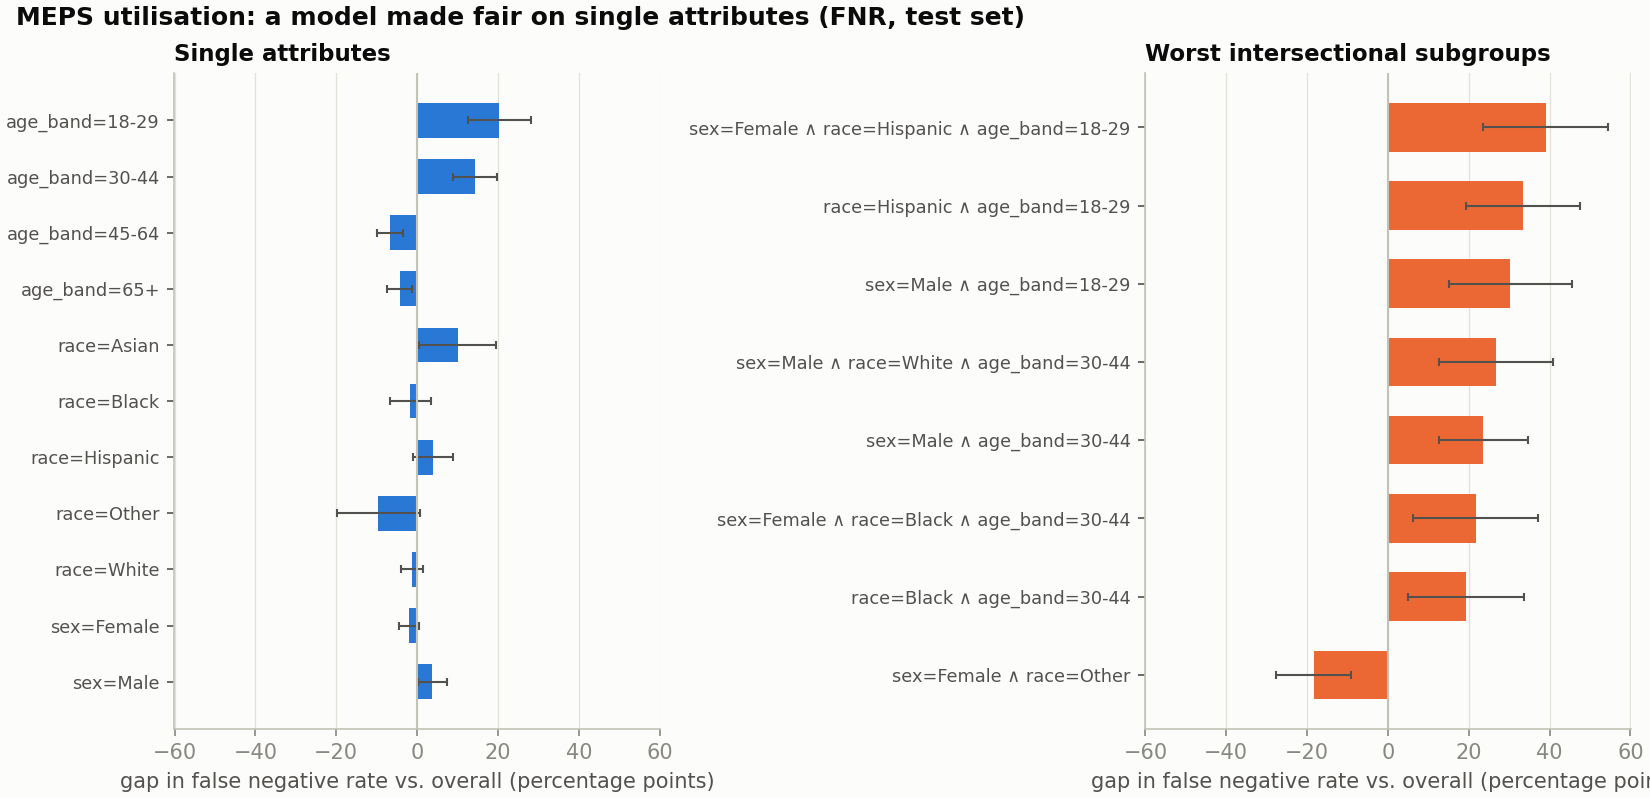

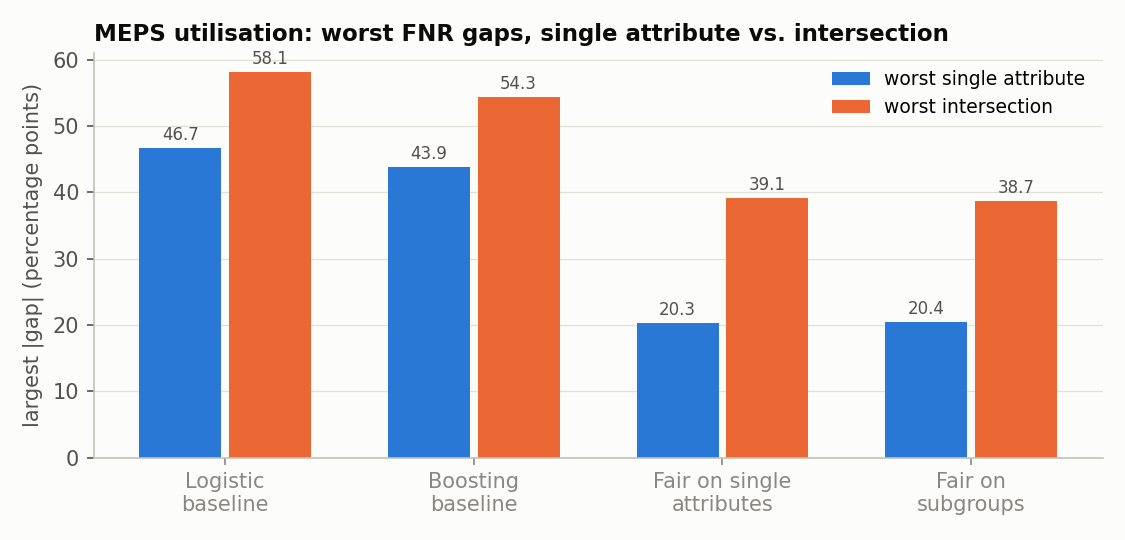

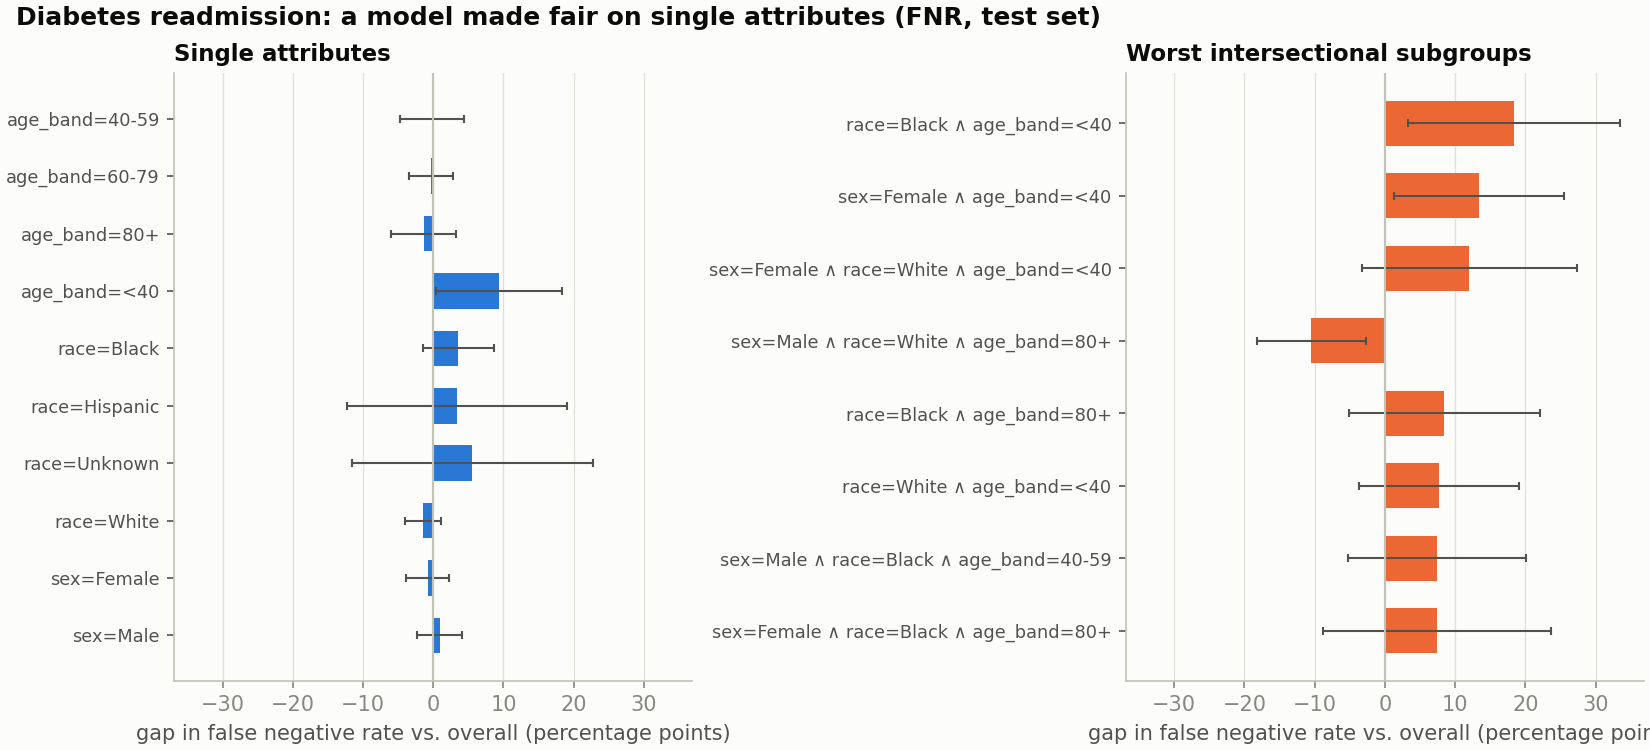

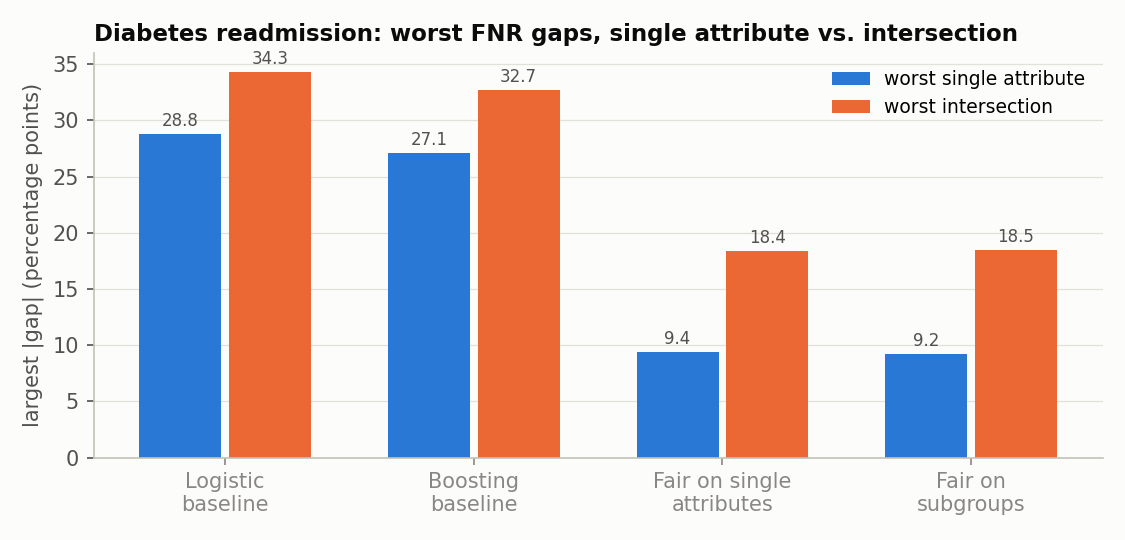

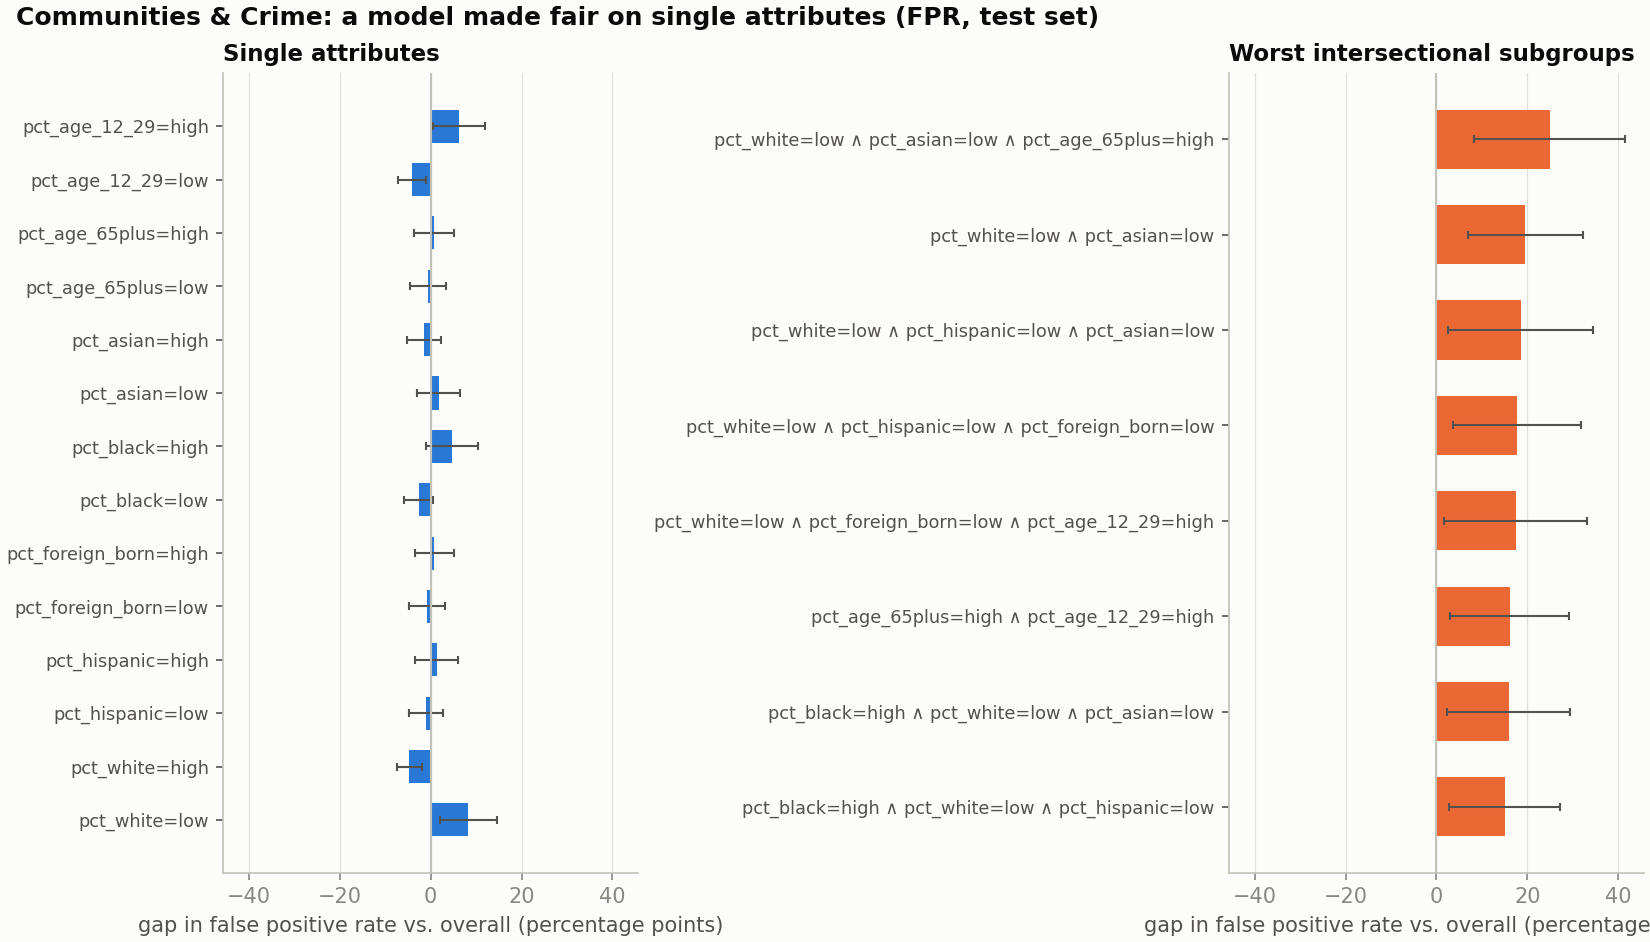

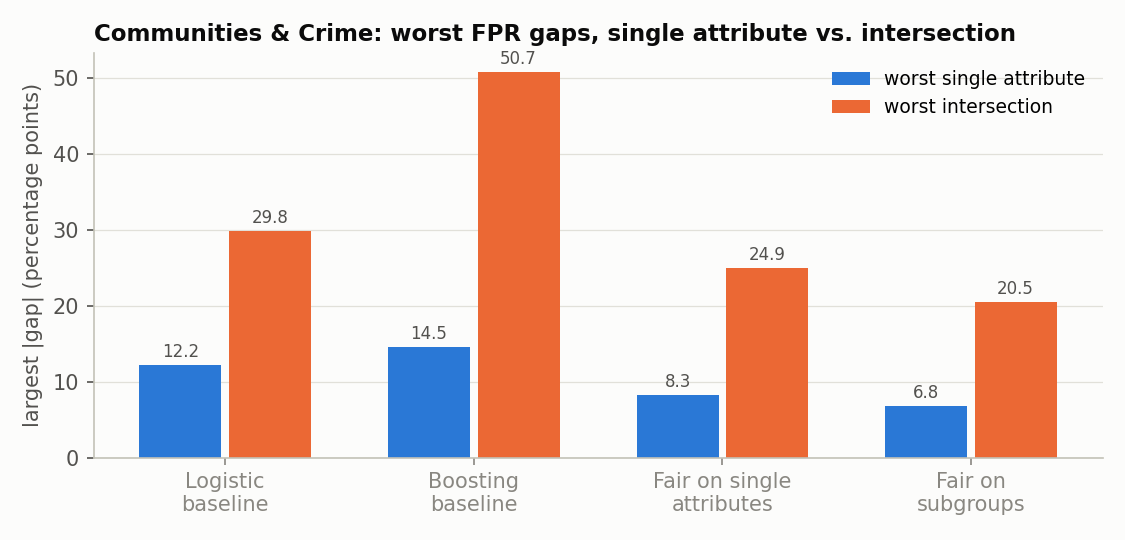

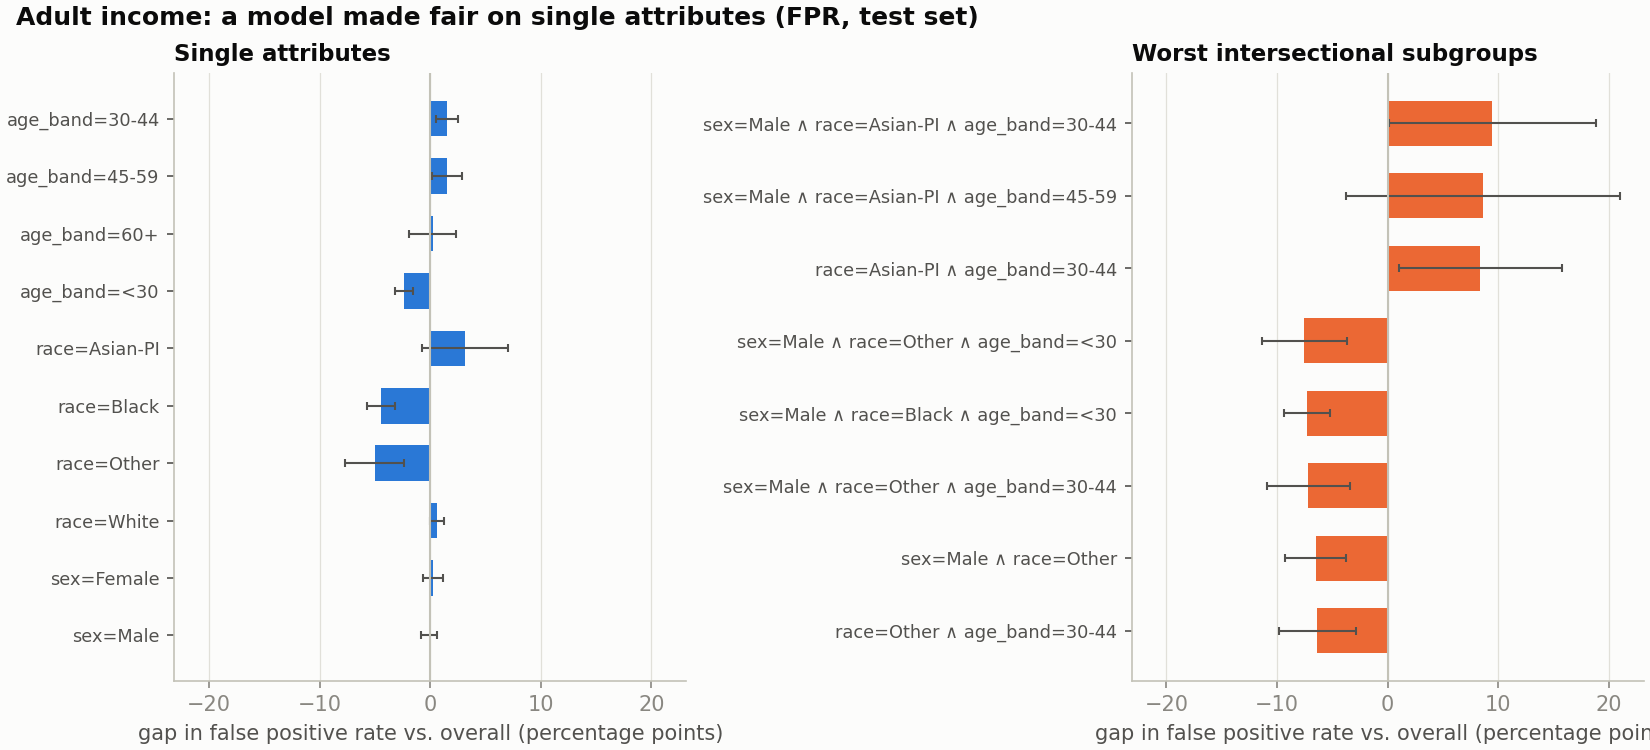

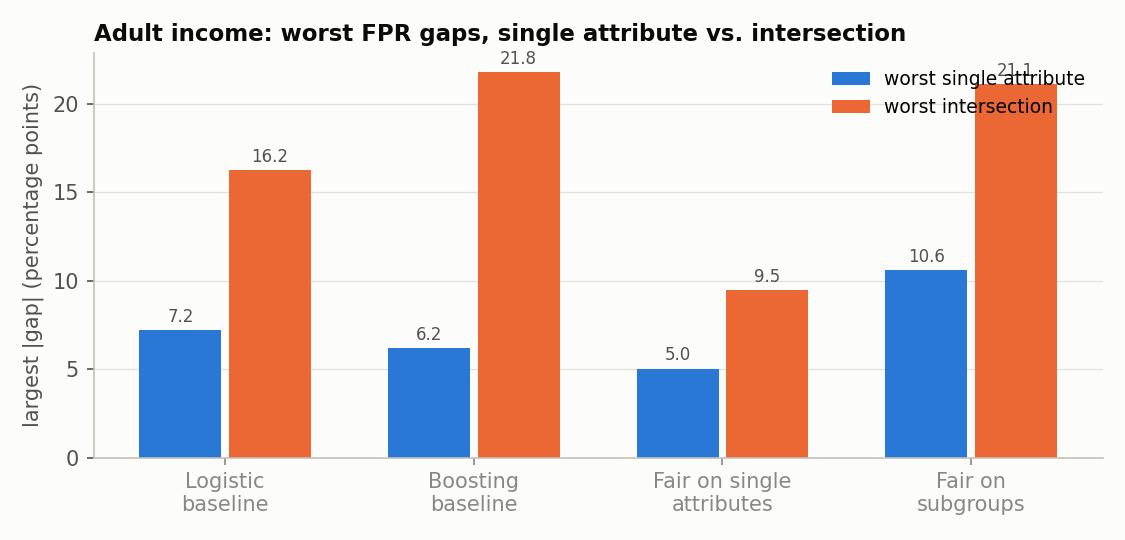

In [4]:
for n in R:
    display(Image(f'../figures/{n}_gerrymandering.png'))
    display(Image(f'../figures/{n}_worst_gaps.png'))

## 4. Accuracy–fairness trade-off

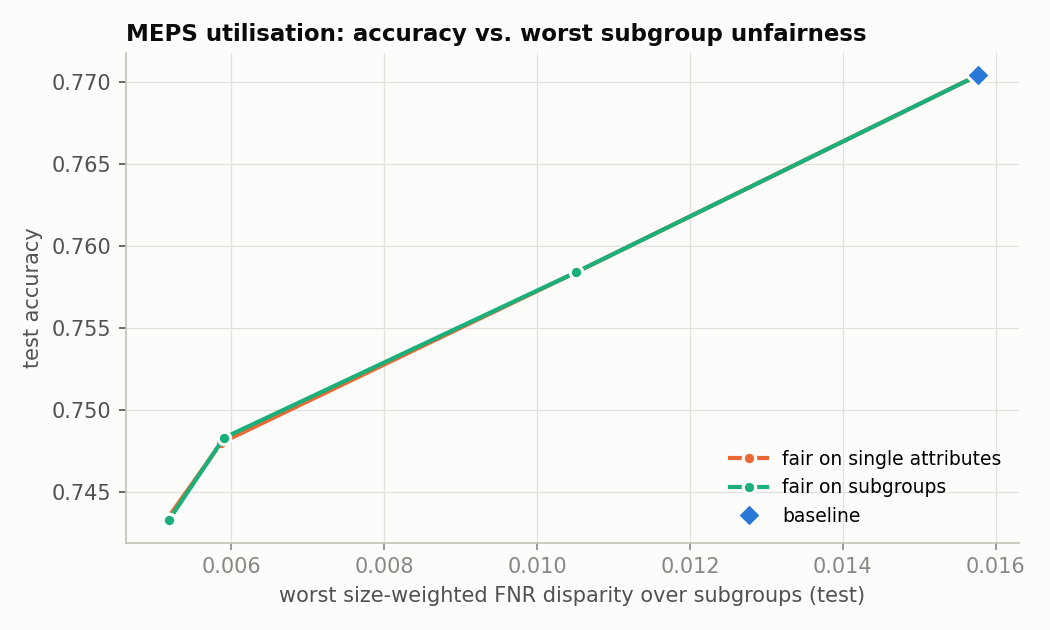

,gamma,accuracy,balanced_accuracy,max_weighted_gap,worst_intersection_gap,worst_single_gap
0,0.0200,0.7704,0.7601,0.0158,0.5809,0.4669
1,0.0100,0.7584,0.7510,0.0105,0.5128,0.3487
2,0.0050,0.7483,0.7390,0.0059,0.4492,0.2645
3,0.0025,0.7433,0.7340,0.0052,0.3873,0.2038
4,0.0010,0.7433,0.7340,0.0052,0.3873,0.2038


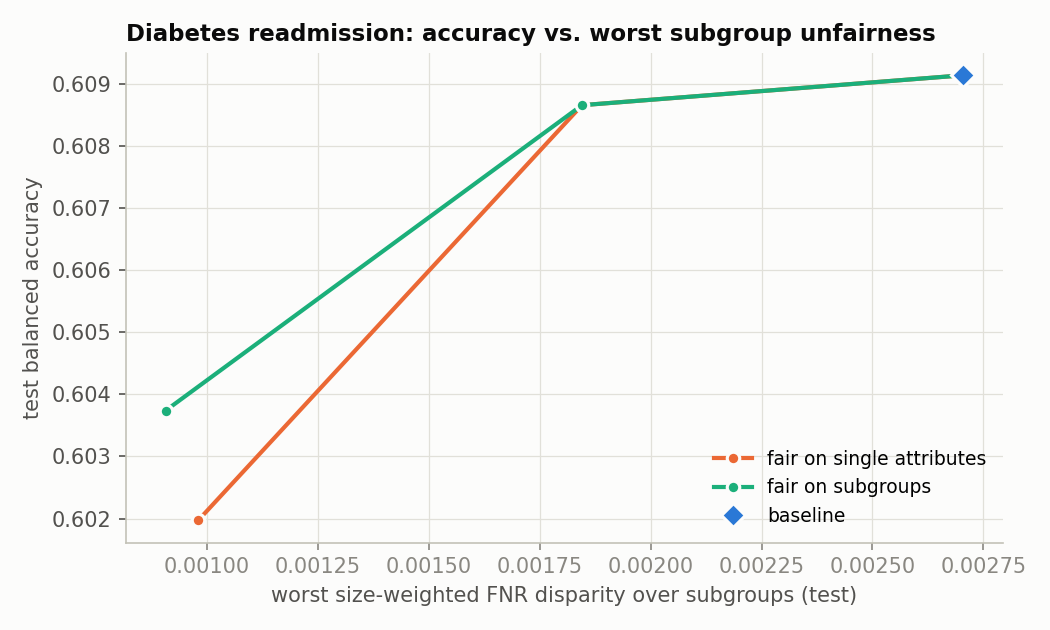

,gamma,accuracy,balanced_accuracy,max_weighted_gap,worst_intersection_gap,worst_single_gap
0,0.0200,0.6784,0.6091,0.0027,0.3429,0.2876
1,0.0100,0.6784,0.6091,0.0027,0.3429,0.2876
2,0.0050,0.6784,0.6091,0.0027,0.3429,0.2876
3,0.0025,0.6787,0.6087,0.0018,0.3026,0.2156
4,0.0010,0.6735,0.6037,0.0009,0.1848,0.0924


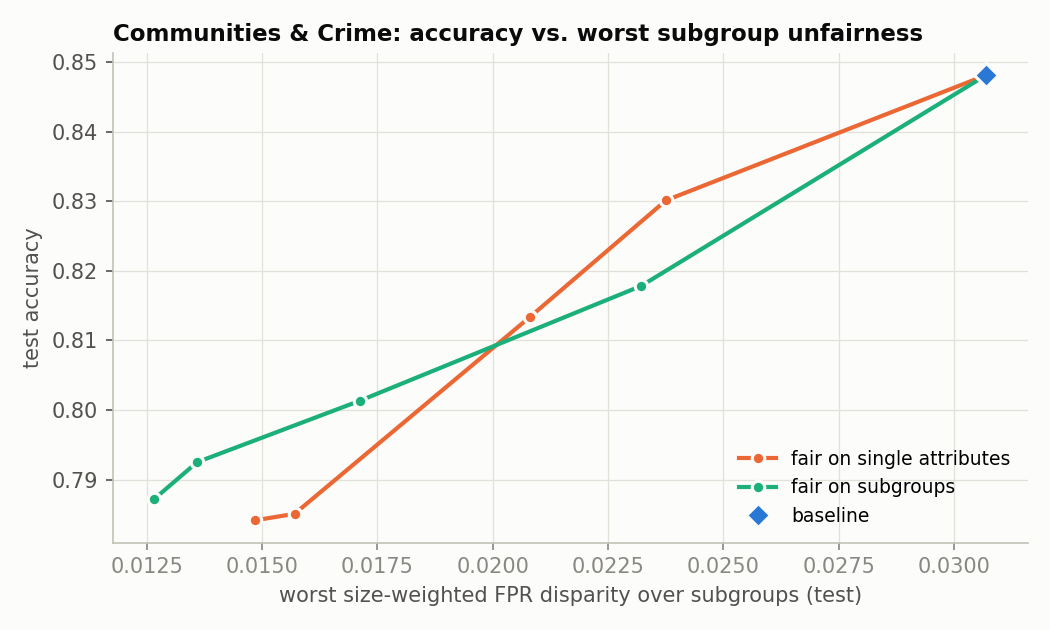

,gamma,accuracy,balanced_accuracy,max_weighted_gap,worst_intersection_gap,worst_single_gap
0,0.0200,0.8481,0.8003,0.0307,0.2981,0.1218
1,0.0100,0.8178,0.7662,0.0232,0.2809,0.0921
2,0.0050,0.8013,0.7465,0.0171,0.2050,0.0679
3,0.0025,0.7925,0.7382,0.0136,0.1579,0.0539
4,0.0010,0.7872,0.7321,0.0127,0.1432,0.0494


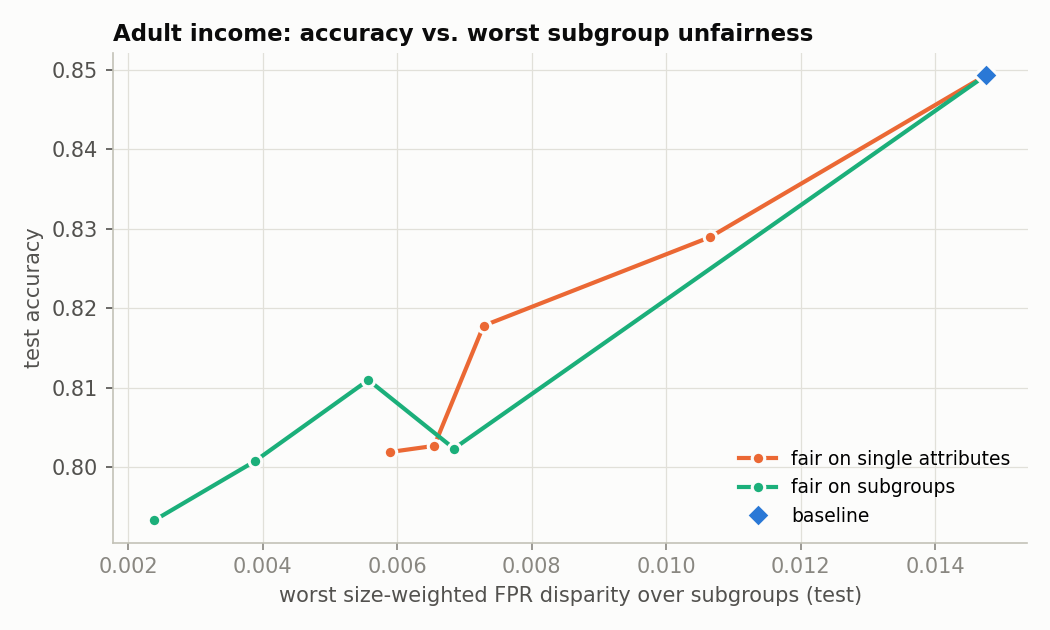

,gamma,accuracy,balanced_accuracy,max_weighted_gap,worst_intersection_gap,worst_single_gap
0,0.0200,0.8493,0.7677,0.0148,0.1622,0.0722
1,0.0100,0.8023,0.7198,0.0068,0.2501,0.1179
2,0.0050,0.8110,0.7218,0.0056,0.2111,0.1057
3,0.0025,0.8007,0.7163,0.0039,0.1506,0.0838
4,0.0010,0.7933,0.7085,0.0024,0.1075,0.0612


In [5]:
for n in R:
    display(Image(f'../figures/{n}_tradeoff.png'))
    display(pd.DataFrame(R[n]['tradeoff']['subgroup_fair']).round(4))

## 5. How clinical risk scores are actually used

A care-management programme enrols the top 20% of patients by risk. Who is missed, are scores calibrated across subgroups, and (MEPS) do patients with the same score have the same level of illness across races?

meps worst missed (FNR) at top-20%: race=Hispanic & age_band=18-29 53.7 pp


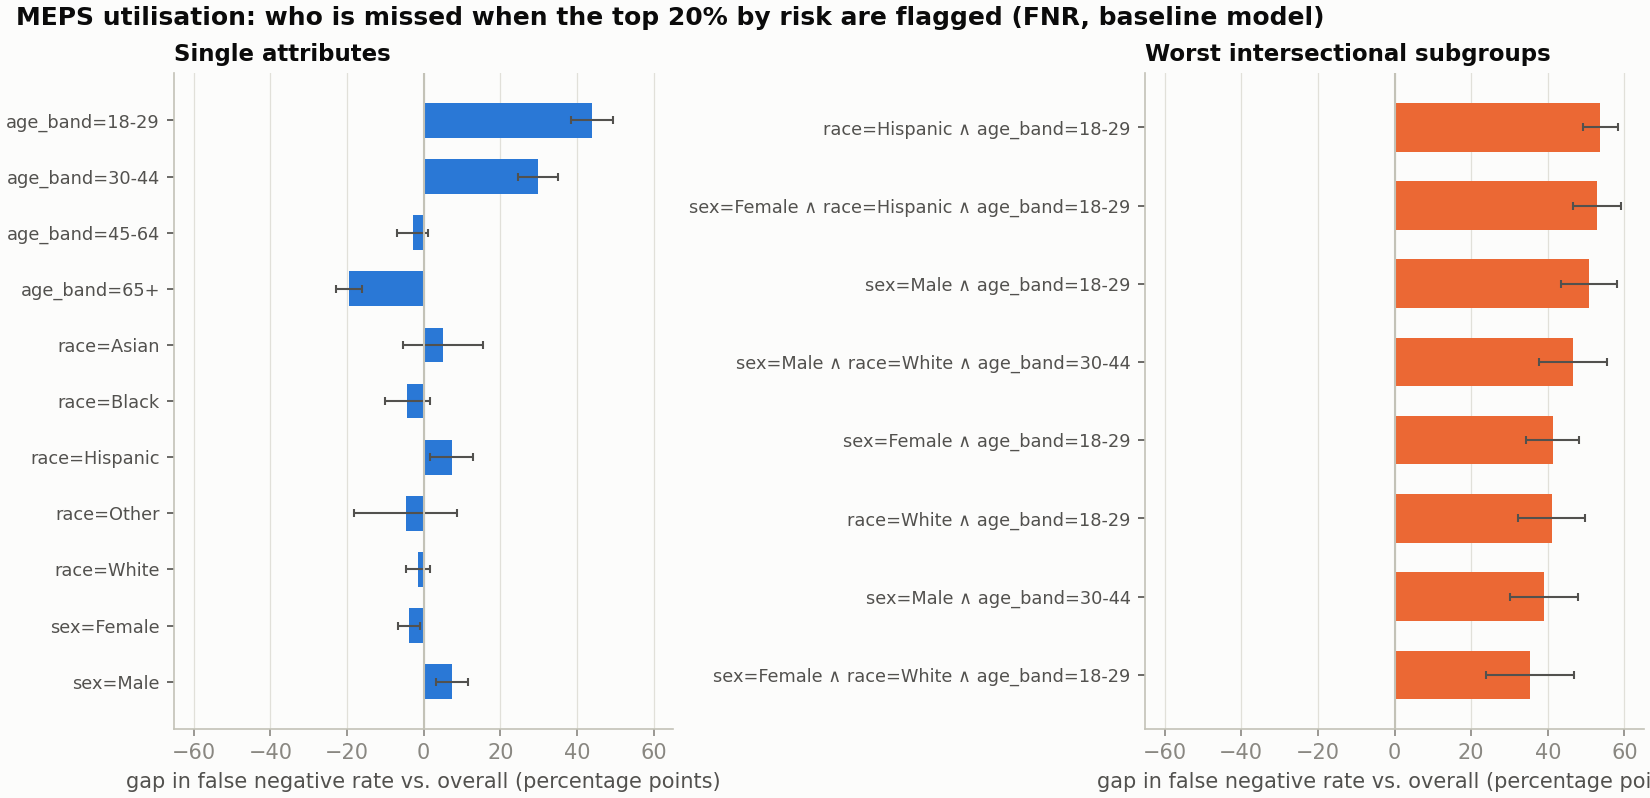

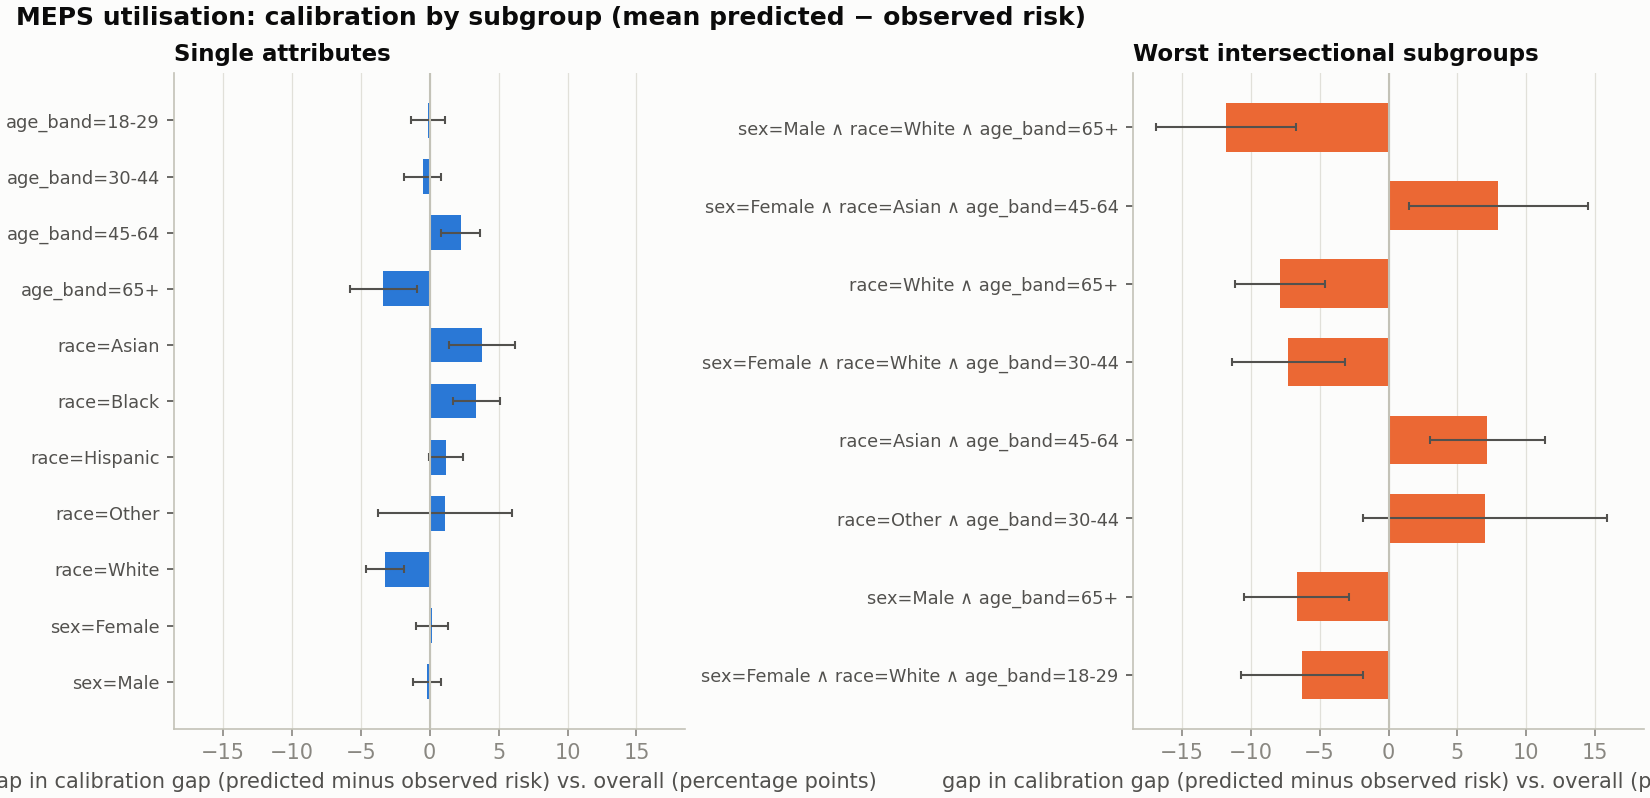

diabetes worst missed (FNR) at top-20%: race=Black & age_band=<40 26.4 pp


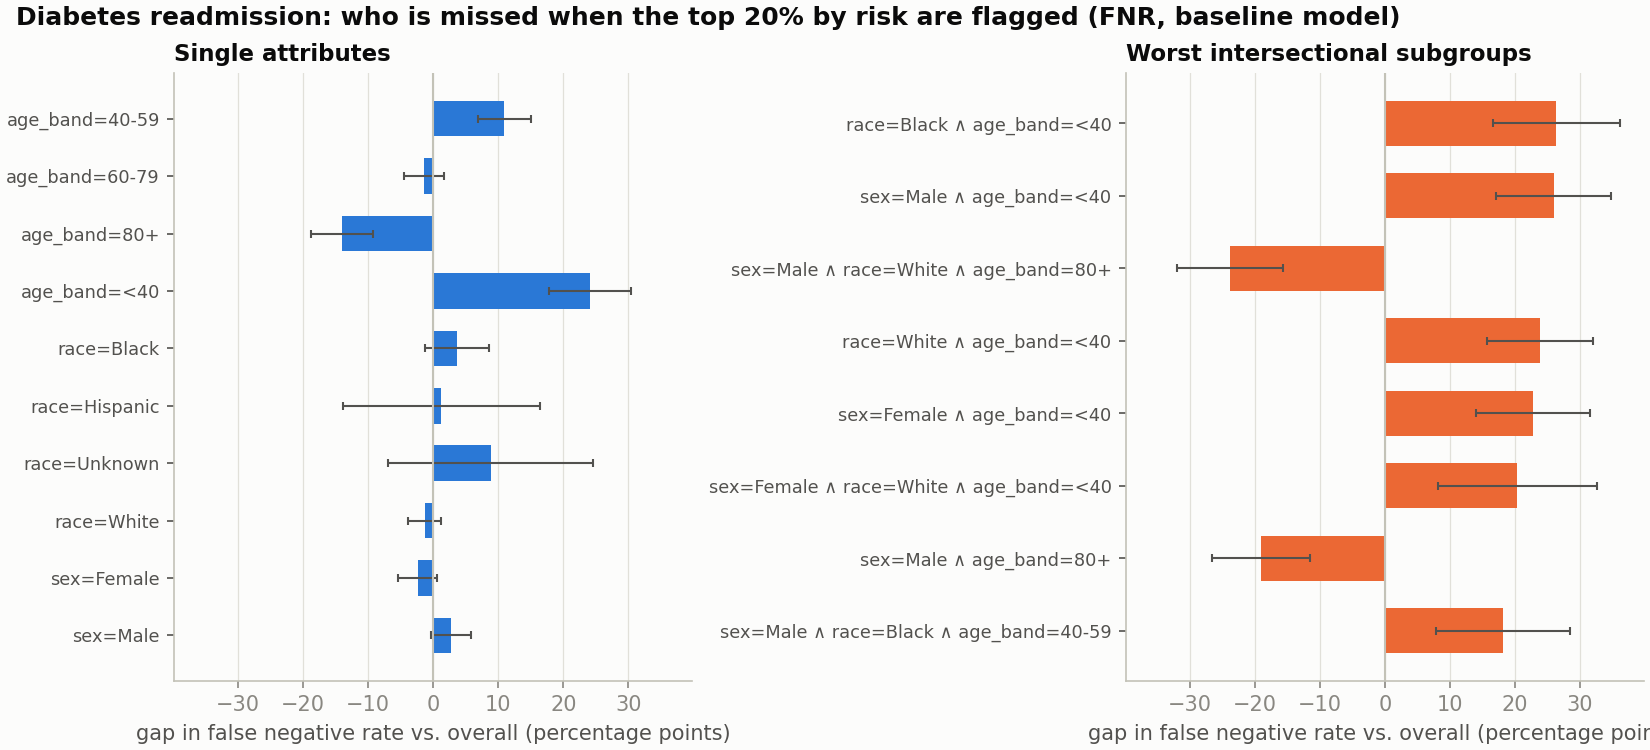

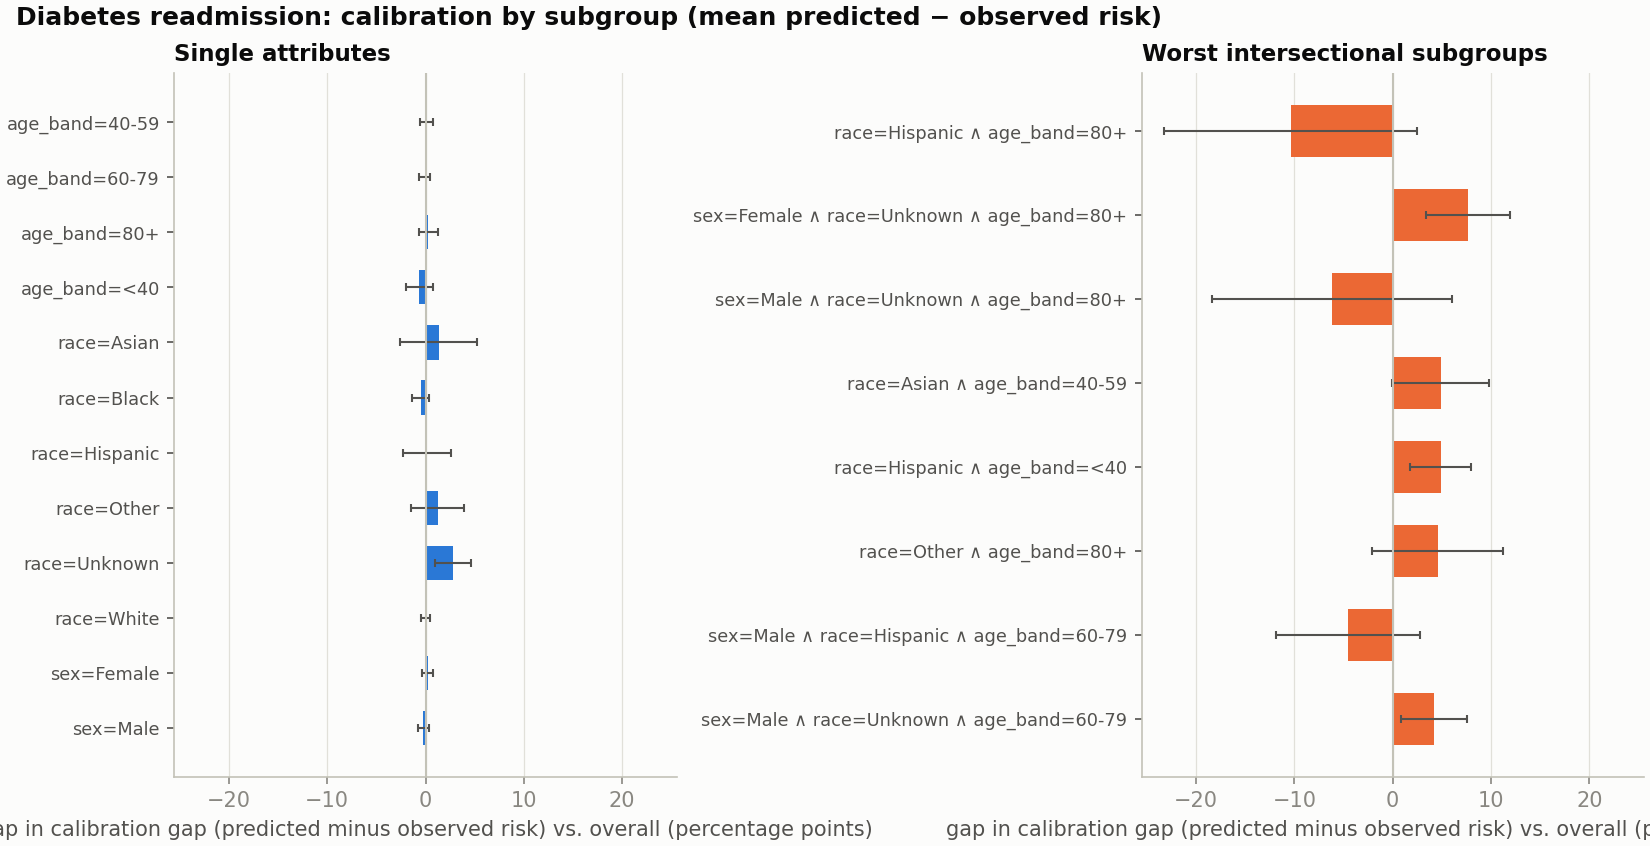

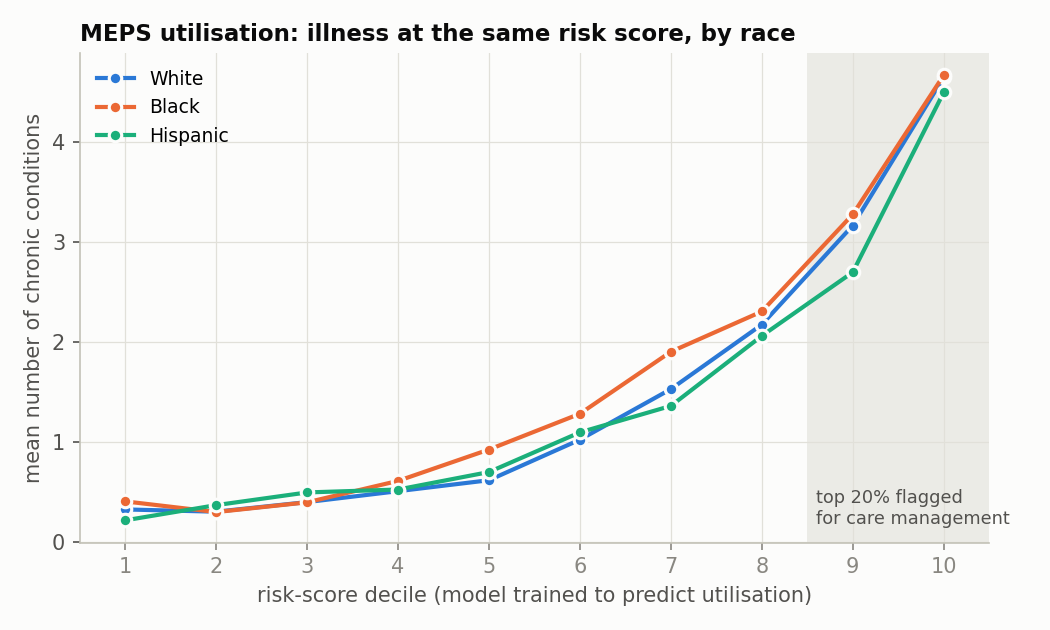

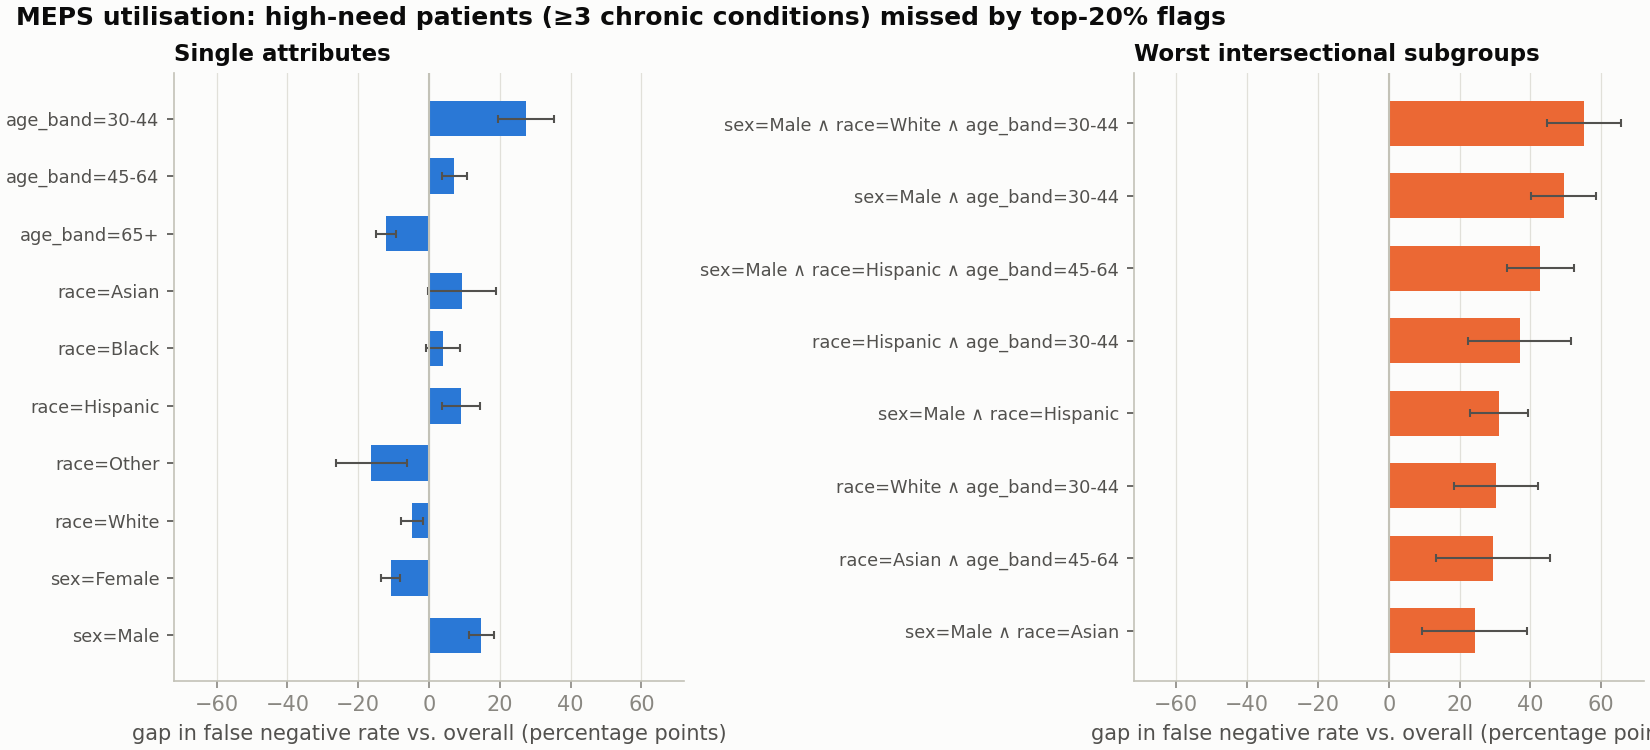

,White,Black,Hispanic
1,0.32,0.40,0.22
2,0.30,0.30,0.37
3,0.40,0.40,0.49
4,0.51,0.61,0.52
5,0.62,0.92,0.70
6,1.02,1.28,1.09
7,1.53,1.90,1.36
8,2.17,2.30,2.06
9,3.16,3.27,2.69
10,4.64,4.66,4.49


In [6]:
for n in ['meps', 'diabetes']:
    c = R[n]['clinical']
    print(n, 'worst missed (FNR) at top-20%:', c['capacity_fnr']['worst_intersection']['subgroup'],
          round(100 * c['capacity_fnr']['worst_intersection']['gap'], 1), 'pp')
    display(Image(f'../figures/{n}_capacity_missed.png'))
    display(Image(f'../figures/{n}_calibration.png'))
display(Image('../figures/meps_need_by_score.png'))
display(Image('../figures/meps_need_missed.png'))
pd.DataFrame(R['meps']['clinical']['need_by_score']['mean_conditions'], index=range(1, 11)).round(2)

## 6. Paper setting and the reference implementation

Linear-threshold subgroups over the 18 protected attributes used in the authors' GerryFair repository, and the effect of the indexing issue in its cost update (our port; see README).

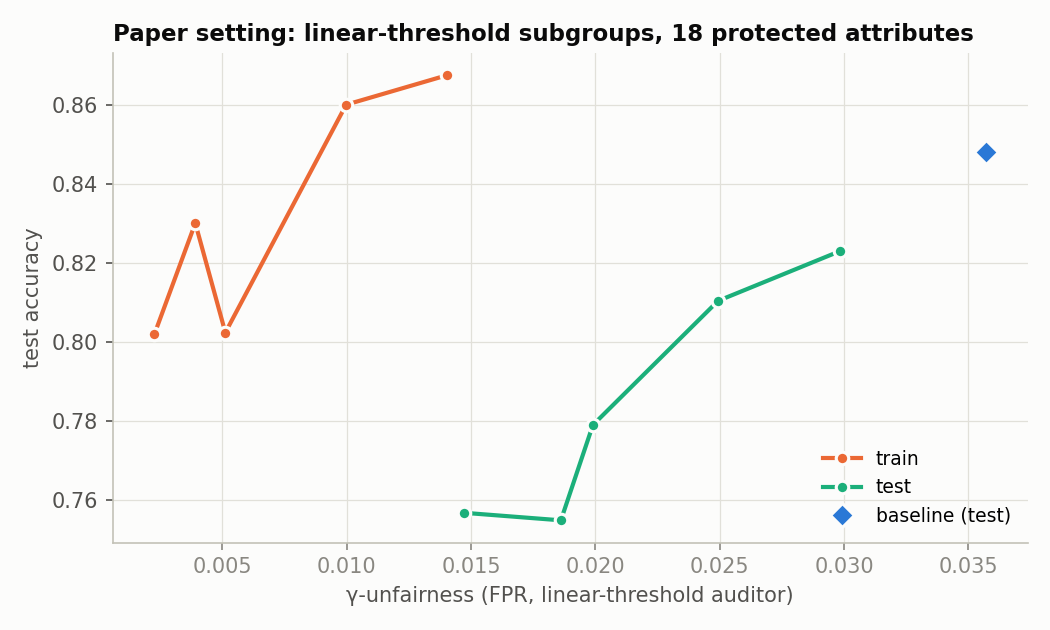

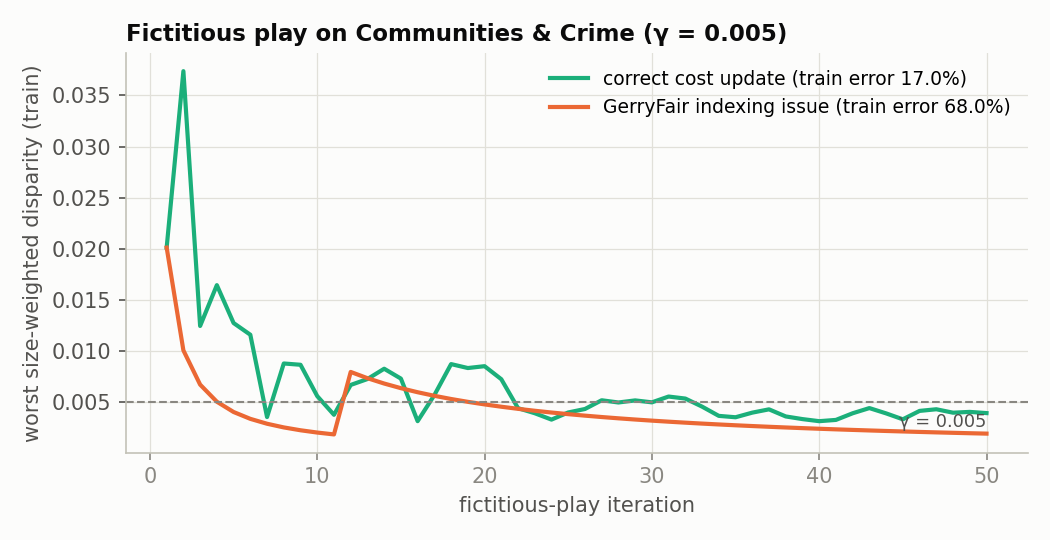

,fixed,with_bug
train_error,0.1699,0.6795
train_unfairness,0.0039,0.0019
test_error,0.2211,0.6797
test_unfairness,0.0199,0.0022


In [7]:
display(Image('../figures/communities_paper_tradeoff.png'))
display(Image('../figures/communities_convergence.png'))
pd.DataFrame({k: {a: b for a, b in v.items() if a != 'history'} for k, v in R['communities']['paper']['bug'].items()}).round(4)